# Prétraitement des prix agricoles

Ce notebook documente le chargement, la sélection, les contrôles de qualité et l'exploration descriptive des données communes aux méthodes naïve, ETS et SARIMA.

L'étude retient deux séries définies dans src/config.py :
- Maïs-grain : Ontario (mais_ON).
- Canola : Saskatchewan (canola_SK).
La période étudiée va de janvier 1985 à août 2026, soit 500 mois par série. Les prix sont nominaux, exprimés en dollars par tonne métrique. Les fichiers sources sont conservés sans modification. Les autres provinces présentes dans les sources sont exclues du périmètre étudié.

Le choix des principales provinces productrices délimite le périmètre : leurs prix ne sont pas assimilés à un prix moyen canadien.

## Localisation des fichiers sources

Nous identifions le dossier data du projet et vérifions la présence des fichiers canola.csv et mais.csv. Cette étape permet de contrôler les chemins avant de charger les données.

In [1]:
# Retrouver la racine du projet et charger la configuration commune.
from pathlib import Path
import sys

dossier_courant = Path.cwd().resolve()
racine = next(
    (p for p in [dossier_courant, *dossier_courant.parents]
     if (p / "src" / "config.py").is_file() and (p / "data").is_dir()),
    None,
)
if racine is None:
    raise FileNotFoundError("Ouvrir le notebook dans le dossier du projet.")
if str(racine) not in sys.path:
    sys.path.insert(0, str(racine))

from src import config

dossier_data = config.DOSSIER_DATA
for chemin in config.FICHIERS_SOURCES.values():
    print(chemin.name, ":", "présent" if chemin.is_file() else "absent")
    if not chemin.is_file():
        raise FileNotFoundError(chemin)

mais.csv : présent
canola.csv : présent


## Chargement des données

Les deux fichiers CSV sont chargés dans des tableaux pandas.
L’encodage cp1252 permet de lire correctement les caractères accentués.

Nous affichons les dimensions et les cinq premières lignes de chaque tableau pour vérifier la structure des données importées.

In [2]:
# Lire les fichiers sources sans les modifier.
import numpy as np
import pandas as pd

canola = pd.read_csv(config.FICHIERS_SOURCES["canola"], encoding=config.ENCODAGE_SOURCES)
mais = pd.read_csv(config.FICHIERS_SOURCES["mais"], encoding=config.ENCODAGE_SOURCES)
for nom, tableau in [("Canola", canola), ("Maïs", mais)]:
    print(nom, "- lignes, colonnes :", tableau.shape)
    display(tableau.head())

Canola - lignes, colonnes : (1000, 5)


,date,province,culture,prix,unité
0,1/1/1985,Saskatchewan,Canola,339.82,Dollars par tonne métrique
1,1/1/1985,Alberta,Canola,342.00,Dollars par tonne métrique
2,2/1/1985,Saskatchewan,Canola,341.26,Dollars par tonne métrique
3,2/1/1985,Alberta,Canola,347.27,Dollars par tonne métrique
4,3/1/1985,Saskatchewan,Canola,349.77,Dollars par tonne métrique


Maïs - lignes, colonnes : (1000, 5)


,date,province,culture,prix,unité
0,1/1/1985,Québec,Maïs-grain,161.01,Dollars par tonne métrique
1,1/1/1985,Ontario,Maïs-grain,133.85,Dollars par tonne métrique
2,2/1/1985,Québec,Maïs-grain,164.95,Dollars par tonne métrique
3,2/1/1985,Ontario,Maïs-grain,132.67,Dollars par tonne métrique
4,3/1/1985,Québec,Maïs-grain,154.32,Dollars par tonne métrique


## Organisation et sélection des données
Les fichiers sources peuvent contenir plusieurs provinces. Après normalisation, seules les combinaisons culture-province de config.SERIES sont retenues, dans la période config.DATE_DEBUT à config.DATE_FIN.

Les identifiants des séries sont ajoutés sans modifier les fichiers sources. Tous les contrôles et graphiques suivants concernent uniquement les séries sélectionnées.

In [3]:
# Normaliser les dates et les prix des fichiers sources.
sources = pd.concat([canola, mais], ignore_index=True).rename(columns={"unité": "unite"})
sources["date"] = pd.to_datetime(sources["date"], format=config.FORMAT_DATE_SOURCES)
sources["prix"] = pd.to_numeric(sources["prix"], errors="raise")

# Sélectionner les séries et la période définies dans la configuration.
morceaux = []
for serie, definition in config.SERIES.items():
    masque = (
        sources["culture"].eq(definition["culture"])
        & sources["province"].eq(definition["province"])
        & sources["date"].between(pd.Timestamp(config.DATE_DEBUT), pd.Timestamp(config.DATE_FIN))
    )
    morceau = sources.loc[masque].copy()
    morceau["serie"] = serie
    morceaux.append(morceau)

df = pd.concat(morceaux, ignore_index=True).sort_values(["serie", "date"]).reset_index(drop=True)
print("Lignes sources :", len(sources))
print("Lignes sélectionnées :", len(df))
print("Séries retenues :", sorted(df["serie"].unique()))
display(df.head())


Lignes sources : 2000
Lignes sélectionnées : 1000
Séries retenues : ['canola_SK', 'mais_ON']


,date,province,culture,prix,unite,serie
0,1985-01-01,Saskatchewan,Canola,339.82,Dollars par tonne métrique,canola_SK
1,1985-02-01,Saskatchewan,Canola,341.26,Dollars par tonne métrique,canola_SK
2,1985-03-01,Saskatchewan,Canola,349.77,Dollars par tonne métrique,canola_SK
3,1985-04-01,Saskatchewan,Canola,364.36,Dollars par tonne métrique,canola_SK
4,1985-05-01,Saskatchewan,Canola,359.99,Dollars par tonne métrique,canola_SK


## Contrôle des valeurs manquantes et des doublons
Pour chaque série, nous vérifions les dates de début et de fin, le nombre de lignes et le nombre de prix manquants.

Nous recherchons également les doublons selon la combinaison « série + date », qui doit être unique.
Les anomalies sont affichées avant toute correction.

In [4]:
# Contrôler les effectifs, les doublons, les prix et les unités.
resume = df.groupby(["serie", "culture", "province"]).agg(
    debut=("date", "min"), fin=("date", "max"),
    nombre_lignes=("date", "size"),
    prix_manquants=("prix", lambda x: x.isna().sum()),
)
display(resume)
doublons = df.duplicated(subset=["serie", "date"], keep=False)
print("Prix manquants :", int(df["prix"].isna().sum()))
print("Lignes en double :", int(doublons.sum()))
assert set(df["serie"]) == set(config.LISTE_SERIES), "Série absente ou inattendue"
assert not doublons.any(), "Dates en double"
assert np.isfinite(df["prix"].to_numpy()).all(), "Prix manquant ou non fini"
assert df["prix"].gt(0).all(), "Les modèles logarithmiques exigent des prix positifs"
assert df["unite"].notna().all() and df["unite"].eq(config.UNITE_SOURCES).all(), "Unité invalide"


,,,debut,fin,nombre_lignes,prix_manquants
serie,culture,province,,,,
canola_SK,Canola,Saskatchewan,1985-01-01,2026-08-01,500,0
mais_ON,Maïs-grain,Ontario,1985-01-01,2026-08-01,500,0


Prix manquants : 0
Lignes en double : 0


## Vérification du calendrier mensuel

Nous comparons les dates de chaque série au calendrier mensuel attendu, de janvier 1985 à août 2026.

Ce contrôle permet de repérer les mois absents et les dates qui ne correspondent pas au calendrier attendu. 

Une ligne présente avec un prix manquant est distinguée d’un mois entièrement absent du tableau.

In [5]:
# Vérifier que chaque série respecte le calendrier mensuel attendu.
calendrier = pd.date_range(config.DATE_DEBUT, config.DATE_FIN, freq="MS")
assert len(calendrier) == config.NB_MOIS_ATTENDU
for serie, groupe in df.groupby("serie"):
    dates = pd.DatetimeIndex(groupe["date"])
    absents = calendrier.difference(dates)
    inattendues = dates.difference(calendrier)
    print(f"{serie} : {len(dates)} mois, {len(absents)} absents, {len(inattendues)} dates inattendues")
    assert len(dates) == len(calendrier) and not len(absents) and not len(inattendues), serie


canola_SK : 500 mois, 0 absents, 0 dates inattendues
mais_ON : 500 mois, 0 absents, 0 dates inattendues


Les deux séries retenues ont chacune 500 observations mensuelles : aucun mois absent, aucun doublon et aucun prix manquant. Le prix manquant de mai 2012 dans les sources concerne le canola en Alberta, une série exclue de l'étude.

### Statistiques descriptives des prix

Les statistiques sont calculées sur les prix observés des deux séries retenues, sans imputation.
La moyenne et la médiane résument le niveau des prix, tandis que l’écart-type et les quartiles décrivent leur dispersion.

In [6]:
# Calculer les statistiques descriptives par culture et province.
statistiques = (
    df.groupby(["culture", "province"])["prix"]
    .describe()
    .rename(columns={
        
        "count": "prix_observes",
        "mean": "moyenne",
        "std": "ecart_type",
        "min": "minimum",
        "25%": "Q1",
        "50%": "mediane",
        "75%": "Q3",
        "max": "maximum"
    })
)

display(statistiques.round(2))


,,prix_observes,moyenne,ecart_type,minimum,Q1,mediane,Q3,maximum
culture,province,,,,,,,,
Canola,Saskatchewan,500.0,418.51,167.98,176.96,274.92,383.18,494.68,1101.49
Maïs-grain,Ontario,500.0,171.66,59.24,85.61,120.23,155.54,206.91,341.54


## Commentaire:
La moyenne des prix nominaux est d'environ 418,51 dollars par tonne pour le canola en Saskatchewan et de 171,66 dollars par tonne pour le maïs-grain en Ontario. Dans les deux séries, la moyenne dépasse la médiane, ce qui est compatible avec l'influence de prix élevés sur la moyenne.

La dispersion des niveaux de prix en dollars par tonne est plus forte pour le canola. Cette différence doit être interprétée en tenant compte des niveaux de prix propres à chaque produit. Les deux séries comptent 500 prix observés. Ces statistiques ne sont pas corrigées de l'inflation.

## Exploration graphique des prix

Les deux séries sont tracées séparément pour observer les mouvements de prix et les valeurs inhabituelles. Les prix extrêmes ne sont pas supprimés sans justification. Cette exploration descriptive de l'ensemble de la période ne remplace pas une analyse temporelle dédiée ni l'évaluation chronologique des prévisions.

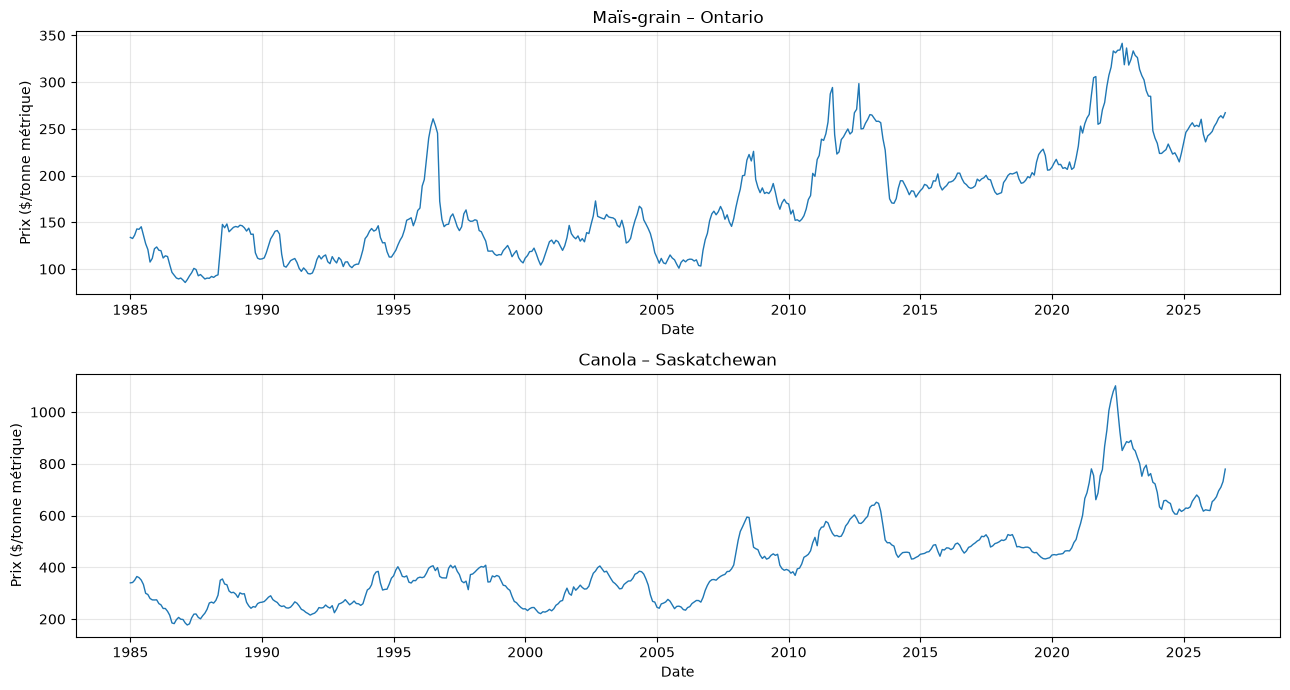

In [7]:
# Matplotlib doit être installé dans l'environnement du projet.
import matplotlib.pyplot as plt

# Tracer séparément les deux séries de prix.
fig, axes = plt.subplots(len(config.LISTE_SERIES), 1, figsize=(13, 7), squeeze=False)
for ax, serie in zip(axes.flat, config.LISTE_SERIES):
    groupe = df.loc[df["serie"].eq(serie)]
    ax.plot(groupe["date"], groupe["prix"], linewidth=1)
    ax.set_title(config.LIBELLES_SERIES[serie])
    ax.set_xlabel("Date")
    ax.set_ylabel("Prix ($/tonne métrique)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Analyse visuelle des prix mensuels

Les deux séries présentent des phases de hausse et de baisse et des prix particulièrement élevés autour de 2022. Ces observations sont conservées : leur caractère extrême ne démontre pas une erreur de saisie.

À cette échelle, les courbes ne suffisent pas à établir une saisonnalité annuelle. L'analyse de la tendance, de la saisonnalité et de la désaisonnalisation doit être complétée dans l'analyse temporelle du projet. Les graphiques ne permettent pas, à eux seuls, d'attribuer les mouvements observés à des causes économiques précises.

Cette exploration décrit les mouvements des prix, mais ne permet pas d’en établir les causes ni de choisir à elle seule le meilleur modèle de prévision.

## Données préparées : aucune imputation nécessaire
Les séries Ontario et Saskatchewan sont complètes. Aucune interpolation n'est appliquée. Le marqueur prix_impute reste présent pour respecter le contrat commun, avec la valeur False sur toutes les lignes.

Le tableau est organisé selon config.COLONNES_SERIES. Le notebook ne réécrit pas data/series.csv : sa génération reste la responsabilité de scripts/preparer_donnees.py.


In [8]:
# Préparer le tableau au format commun, sans imputation.
df_prepare = df.copy()
df_prepare["produit"] = df_prepare["serie"].map(config.PRODUIT_PAR_SERIE)
df_prepare["province"] = df_prepare["serie"].map(config.PROVINCE_PAR_SERIE)
df_prepare["prix_impute"] = False
df_prepare = df_prepare[config.COLONNES_SERIES].sort_values(["serie", "date"]).reset_index(drop=True)
assert len(df_prepare) == len(config.LISTE_SERIES) * config.NB_MOIS_ATTENDU
assert not df_prepare["prix_impute"].any()
display(df_prepare.head())
print("Lignes préparées :", len(df_prepare))
print("Prix imputés :", int(df_prepare["prix_impute"].sum()))


,date,serie,produit,province,prix,prix_impute
0,1985-01-01,canola_SK,canola,SK,339.82,False
1,1985-02-01,canola_SK,canola,SK,341.26,False
2,1985-03-01,canola_SK,canola,SK,349.77,False
3,1985-04-01,canola_SK,canola,SK,364.36,False
4,1985-05-01,canola_SK,canola,SK,359.99,False


Lignes préparées : 1000
Prix imputés : 0


## Concordance avec le script commun
Nous comparons le tableau préparé en mémoire au résultat des fonctions du script officiel, sans appeler sa fonction d'écriture. Cela permet de détecter une divergence entre la documentation et la préparation commune.

In [9]:
# Vérifier la concordance avec le script commun, sans écrire de fichier.
from scripts.preparer_donnees import lire_sources, selectionner_series, imputer, verifier

reference = imputer(selectionner_series(lire_sources()))
assert verifier(reference), "Échec des contrôles du script commun"
reference = reference[config.COLONNES_SERIES].sort_values(["serie", "date"]).reset_index(drop=True)
pd.testing.assert_frame_equal(df_prepare, reference, check_dtype=False)
print("Concordance exacte avec le script commun pour les sources fournies.")



Valeurs estimées

Vérifications par série
  série      début    fin       mois  manquants  estimés  doublons  trous
  mais_ON    1985-01  2026-08    500          0        0         0      0
  canola_SK  1985-01  2026-08    500          0        0         0      0

Vérifications globales
  [OK] 2 séries présentes (2 trouvées)
  [OK] aucune valeur manquante après estimation (0 trouvée(s))
  [OK] unité unique « Dollars par tonne métrique » (trouvé : ['Dollars par tonne métrique'])
  [OK] dates consécutives, sans trou ni doublon, dans chaque série
  [OK] toutes les séries débutent en 1985-01
  [OK] même date de fin pour toutes les séries (['2026-08'])
  [OK] même nombre de mois pour toutes les séries ([500])
Concordance exacte avec le script commun pour les sources fournies.


## Utilisation des données préparées

Les données préparées concernent le maïs-grain en Ontario et le canola en Saskatchewan. Elles sont exprimées en dollars nominaux par tonne métrique.

Le fichier commun 'data/series.csv' est produit par 'scripts/preparer_donnees.py' et utilisé par les méthodes naïve, ETS et SARIMA.

Le découpage chronologique est défini dans 'src/config.py' et décrit dans 'docs/protocole.md'. Il comprend un entraînement croissant, six blocs annuels de validation et trois périodes de test de deux ans, avec un bilan global sur les six années de test.

Ce notebook documente le prétraitement et l’exploration descriptive. Le découpage et la transformation logarithmique sont appliqués dans le parcours de modélisation et d’évaluation.